# SARLD — sentiment-routed, regime-gated attention-LSTM for S&P 500 volatility (TensorFlow)

**What is new compared with the earlier notebooks**

| | First notebook | Second notebook (NumPy) | **This notebook** |
|---|---|---|---|
| Sample | 2019–2024 | 2019–2024 | **2008–2024** (prices from Yahoo Finance, 18k headlines) |
| Sentiment | VADER + TextBlob | VADER + TextBlob | **FinBERT** |
| Target | price level | 1-day return, 1-day volatility | **volatility at 1, 5 and 22 days + Value-at-Risk** |
| Regimes | full-sample labels (leaky) | filtered probabilities as inputs | **filtered probabilities drive a gate over expert heads** |
| Sentiment role | input feature | input feature | **router: it decides which expert to trust** (tested against "as input") |
| Benchmarks | none | HAR, ridge, GBM | + **VIX-augmented HAR** |
| Framework | TensorFlow | NumPy | **TensorFlow / Keras** |


## 0. Configuration

In [ ]:
QUICK         = False          # True: 5 key configurations, 2 seeds (trial run). False: everything (paper run).
SEEDS         = [11, 22] if QUICK else [11, 22, 33]
T             = 22             # look-back window (trading days)
TEST_START    = '2013-01-01'   # first out-of-sample day; everything before is the initial training window
BLOCK         = 252            # models are re-estimated every BLOCK trading days
LAG_SENT      = 0              # 1 = use only headlines up to the previous trading day (robustness check)
DETERMINISTIC = True           # bit-reproducible GPU training. If TensorFlow raises an 'UnimplementedError' about
                               # determinism in section 4, set this to False, restart the runtime and run all again.
USE_DRIVE     = False          # True: keep results on Google Drive so nothing is lost if Colab disconnects
OUT           = 'sarld_results'

In [ ]:
import os, sys, json, time, warnings
warnings.filterwarnings('ignore')
if USE_DRIVE:
    from google.colab import drive
    drive.mount('/content/drive'); OUT = '/content/drive/MyDrive/' + OUT
os.makedirs(OUT, exist_ok=True)
import numpy as np, pandas as pd
print('results folder:', OUT)

results folder: sarld_results


## 1. Core library (features, HMM, walk-forward folds, benchmarks, tests)
Pure NumPy / scikit-learn. This part was tested before delivery.

In [ ]:
%%writefile sarld_core.py
"""
SARLD core (NumPy / pandas / scikit-learn part).
Causal features, train-only HMM with forward filtering, purged walk-forward folds,
benchmarks, statistical tests, VaR evaluation. The neural network lives in the TensorFlow cell.
"""
import os, json, pickle, time
import numpy as np, pandas as pd
from scipy import stats
from sklearn.linear_model import Ridge, LinearRegression
from sklearn.ensemble import HistGradientBoostingRegressor

EPS = 1e-12
HORIZONS = (1, 5, 22)
HMAX = max(HORIZONS)
WARMUP = 60

# ----------------------------------------------------------------------------
# 1. Causal feature engineering
# ----------------------------------------------------------------------------
def build_features(df):
    """df columns: date, open, high, low, close, volume, [vix], s_score, s_neg, s_pos, s_disp, s_count.
    Every feature at row t uses information available at the close of day t only."""
    d = df.sort_values('date').reset_index(drop=True).copy()
    c, o, h, l = d['close'], d['open'], d['high'], d['low']
    v = d['volume'].replace(0, np.nan).ffill()
    f = pd.DataFrame({'date': d['date'], 'close': c})
    f['ret'] = np.log(c).diff()
    f['absret'] = f['ret'].abs()
    gk = (0.5 * np.log(h / l) ** 2 - (2 * np.log(2) - 1) * np.log(c / o) ** 2).clip(lower=1e-10)
    f['gkvar'] = gk
    f['lgk'] = 0.5 * np.log(gk)
    f['lgk5'] = 0.5 * np.log(gk.rolling(5).mean())
    f['lgk22'] = 0.5 * np.log(gk.rolling(22).mean())
    f['gap'] = np.log(o / c.shift(1))
    f['intraday'] = np.log(c / o)
    f['lrv5'] = np.log(f['ret'].rolling(5).std() + 1e-6)
    f['lrv20'] = np.log(f['ret'].rolling(20).std() + 1e-6)
    f['negret'] = f['ret'].clip(upper=0)                      # leverage effect
    f['down5'] = np.log(f['negret'].rolling(5).std() + 1e-6)  # downside semi-volatility
    delta = c.diff()
    gain = delta.clip(lower=0).rolling(14).mean(); loss = (-delta.clip(upper=0)).rolling(14).mean()
    f['rsi'] = (100 - 100 / (1 + gain / (loss + 1e-9))) / 100 - 0.5
    macd = c.ewm(span=12, adjust=False).mean() - c.ewm(span=26, adjust=False).mean()
    f['macd_hist'] = (macd - macd.ewm(span=9, adjust=False).mean()) / c
    ma20, sd20 = c.rolling(20).mean(), c.rolling(20).std()
    f['bb_pctb'] = (c - ma20) / (2 * sd20 + 1e-9)
    f['bb_width'] = 4 * sd20 / ma20
    tr = pd.concat([h - l, (h - c.shift(1)).abs(), (l - c.shift(1)).abs()], axis=1).max(axis=1)
    f['atr'] = tr.rolling(14).mean() / c
    f['lvol_ratio'] = np.log(v / v.rolling(20).mean())
    f['mom10'] = c / c.rolling(10).mean() - 1
    f['mom50'] = c / c.rolling(50).mean() - 1
    # D: one-sided multi-scale decomposition
    e5, e20, e60 = [c.ewm(span=k, adjust=False).mean() for k in (5, 20, 60)]
    f['dec_fast'] = (c - e5) / c; f['dec_mid'] = (e5 - e20) / c; f['dec_slow'] = (e20 - e60) / c
    # V: option-implied volatility (optional)
    if 'vix' in d and d['vix'].notna().sum() > 0.9 * len(d):
        vix = d['vix'].ffill()
        f['v_lvix'] = np.log(vix / 100 / np.sqrt(252))           # same units as lgk
        f['v_dvix'] = np.log(vix).diff()
        f['v_vrp'] = f['v_lvix'] - f['lgk22']                    # implied minus realised
    # S: news sentiment
    sc, n = d['s_score'].fillna(0), np.log1p(d['s_count'].fillna(0))
    f['s_score'] = sc; f['s_neg'] = d['s_neg'].fillna(0); f['s_pos'] = d['s_pos'].fillna(0)
    f['s_disp'] = d['s_disp'].fillna(0); f['s_count'] = n; f['s_has'] = (d['s_count'].fillna(0) > 0).astype(float)
    f['s_score_ema5'] = sc.ewm(span=5, adjust=False).mean()
    f['s_neg_ema5'] = f['s_neg'].ewm(span=5, adjust=False).mean()
    f['s_surprise'] = sc - sc.rolling(20).mean()
    f['s_abn_count'] = n - n.rolling(60).mean()
    # targets: log of average GK volatility over the next h days, and next-day return
    for hz in HORIZONS:
        f[f'y_v{hz}'] = 0.5 * np.log(gk.rolling(hz).mean().shift(-hz))
    f['y_ret'] = f['ret'].shift(-1)
    return f

P_COLS = ['ret', 'absret', 'lgk', 'lgk5', 'lgk22', 'gap', 'intraday', 'lrv5', 'lrv20', 'negret', 'down5', 'rsi',
          'macd_hist', 'bb_pctb', 'bb_width', 'atr', 'lvol_ratio', 'mom10', 'mom50']
D_COLS = ['dec_fast', 'dec_mid', 'dec_slow']
V_COLS = ['v_lvix', 'v_dvix', 'v_vrp']
S_COLS = ['s_score', 's_neg', 's_pos', 's_disp', 's_count', 's_has', 's_score_ema5', 's_neg_ema5', 's_surprise', 's_abn_count']
S_GATE = ['s_score_ema5', 's_neg_ema5', 's_surprise', 's_abn_count', 's_disp']   # what the router sees
R_COLS = ['reg_calm', 'reg_normal', 'reg_turb']
Y_COLS = [f'y_v{h}' for h in HORIZONS]
HAR_COLS = ['lgk', 'lgk5', 'lgk22']

# ----------------------------------------------------------------------------
# 2. Gaussian HMM (EM on training data, causal forward filter afterwards)
# ----------------------------------------------------------------------------
def _log_gauss(X, mu, cov):
    k = X.shape[1]
    L = np.linalg.cholesky(cov)
    sol = np.linalg.solve(L, (X - mu).T)
    return -0.5 * (k * np.log(2 * np.pi) + 2 * np.log(np.diag(L)).sum() + (sol ** 2).sum(0))


class GaussianHMM:
    """K-state full-covariance Gaussian HMM. Deterministic initialisation by
    sorting on the last observation column (volatility)."""

    def __init__(self, k=3, n_iter=300, tol=1e-4, reg=1e-4):
        self.k, self.n_iter, self.tol, self.reg = k, n_iter, tol, reg

    def _emis(self, X):
        return np.column_stack([_log_gauss(X, self.mu[j], self.cov[j]) for j in range(self.k)])

    def _forward(self, B):
        T = len(B)
        alpha = np.zeros((T, self.k)); cs = np.zeros(T)
        a = self.pi * B[0]; cs[0] = a.sum(); alpha[0] = a / cs[0]
        for t in range(1, T):
            a = (alpha[t - 1] @ self.A) * B[t]
            cs[t] = a.sum(); alpha[t] = a / cs[t]
        return alpha, cs

    def fit(self, X):
        T, dim = X.shape
        order = np.argsort(X[:, -1])
        self.mu = np.array([X[idx].mean(0) for idx in np.array_split(order, self.k)])
        self.cov = np.array([np.cov(X[idx].T) + self.reg * np.eye(dim)
                             for idx in np.array_split(order, self.k)])
        self.A = np.full((self.k, self.k), 0.05 / (self.k - 1))
        np.fill_diagonal(self.A, 0.95)
        self.pi = np.full(self.k, 1.0 / self.k)
        prev = -np.inf
        for it in range(self.n_iter):
            logB = self._emis(X)
            m = logB.max(1, keepdims=True)
            B = np.exp(logB - m)
            alpha, cs = self._forward(B)
            ll = np.log(cs).sum() + m.sum()
            beta = np.ones((T, self.k))
            for t in range(T - 2, -1, -1):
                beta[t] = (self.A @ (B[t + 1] * beta[t + 1])) / cs[t + 1]
            gamma = alpha * beta
            gamma /= gamma.sum(1, keepdims=True)
            xi = (alpha[:-1, :, None] * self.A[None] * (B[1:] * beta[1:])[:, None, :]
                  / cs[1:, None, None]).sum(0)
            self.pi = gamma[0] / gamma[0].sum()
            self.A = xi / xi.sum(1, keepdims=True)
            for j in range(self.k):
                w = gamma[:, j]; s = w.sum()
                self.mu[j] = (w[:, None] * X).sum(0) / s
                diff = X - self.mu[j]
                self.cov[j] = (w[:, None, None] * diff[:, :, None] * diff[:, None, :]).sum(0) / s \
                              + self.reg * np.eye(dim)
            self.n_iter_ = it + 1
            self.converged_ = abs(ll - prev) < self.tol
            if self.converged_:
                break
            prev = ll
        # canonical order: ascending mean of last column (volatility)
        o = np.argsort(self.mu[:, -1])
        self.mu, self.cov, self.pi = self.mu[o], self.cov[o], self.pi[o]
        self.A = self.A[o][:, o]
        return self

    def filter(self, X):
        """P(state_t | x_1..x_t): uses no future observations."""
        logB = self._emis(X)
        B = np.exp(logB - logB.max(1, keepdims=True))
        return self._forward(B)[0]

    def smooth_labels(self, X):
        """Viterbi path (uses the whole sequence, i.e. NOT causal)."""
        logB = self._emis(X); T = len(X)
        lA = np.log(self.A + EPS)
        dlt = np.log(self.pi + EPS) + logB[0]
        psi = np.zeros((T, self.k), int)
        for t in range(1, T):
            cand = dlt[:, None] + lA
            psi[t] = cand.argmax(0)
            dlt = cand.max(0) + logB[t]
        path = np.zeros(T, int); path[-1] = dlt.argmax()
        for t in range(T - 2, -1, -1):
            path[t] = psi[t + 1, path[t + 1]]
        return path



# ----------------------------------------------------------------------------
# 3. Purged expanding walk-forward folds
# ----------------------------------------------------------------------------
def prepare(df, T=22, test_start='2013-01-01', init_train=500, block=252):
    f = build_features(df)
    n = len(f)
    has_v = 'v_lvix' in f
    base = P_COLS + D_COLS + (V_COLS if has_v else []) + S_COLS
    first, last = WARMUP + T - 1, n - 1 - HMAX
    ts = int(np.searchsorted(f['date'].values, np.datetime64(test_start)))
    ts = max(ts, first + init_train)
    folds = []
    while ts <= last:
        te = min(ts + block, last + 1)
        if last + 1 - te < block // 3: te = last + 1          # absorb a short tail into the last fold
        rows = slice(WARMUP, ts)
        mu, sd = f[base].iloc[rows].mean(), f[base].iloc[rows].std() + 1e-9
        Z = ((f[base] - mu) / sd).clip(-6, 6)
        hs = f[['ret', 'lgk']].iloc[rows]
        Xh = ((f[['ret', 'lgk']] - hs.mean()) / hs.std()).values
        hmm = GaussianHMM(3).fit(Xh[WARMUP:ts])
        probs = np.zeros((n, 3)); probs[WARMUP:te] = hmm.filter(Xh[WARMUP:te])
        for j, cn in enumerate(R_COLS): Z[cn] = probs[:, j]
        Z = Z.fillna(0.0)
        tr = np.arange(first, ts - HMAX + 1)                  # purge: targets must end by day ts
        folds.append(dict(ts=ts, te=te, tr=tr, Z=Z, hmm_conv=bool(hmm.converged_), hmm_iter=hmm.n_iter_,
                          hmm_mu=hmm.mu * hs.std().values + hs.mean().values, hmm_A=hmm.A,
                          ymu=f[Y_COLS].values[tr].mean(0), ysd=f[Y_COLS].values[tr].std(0)))
        ts = te
    return dict(f=f, folds=folds, first=first, last=last, has_v=has_v, T=T)


def make_windows(M, idx, T):
    return np.stack([M[i - T + 1:i + 1] for i in idx]).astype('float32')


def variant_table(has_v):
    PDV = P_COLS + D_COLS + (V_COLS if has_v else [])
    V = {
        # name        sequence inputs          gate inputs        K  attention skip
        'full':    dict(seq=PDV,                   gate=R_COLS + S_GATE, K=3, attention=True,  skip=True),   # sentiment routes
        'S_input': dict(seq=PDV + S_COLS,          gate=R_COLS,          K=3, attention=True,  skip=True),   # sentiment as feature
        'S_both':  dict(seq=PDV + S_COLS,          gate=R_COLS + S_GATE, K=3, attention=True,  skip=True),
        'noS':     dict(seq=PDV,                   gate=R_COLS,          K=3, attention=True,  skip=True),
        'noR':     dict(seq=PDV,                   gate=S_GATE,          K=3, attention=True,  skip=True),
        'noGate':  dict(seq=PDV + S_COLS + R_COLS, gate=[],              K=1, attention=True,  skip=True),   # usual hybrid
        'noAttn':  dict(seq=PDV,                   gate=R_COLS + S_GATE, K=3, attention=False, skip=True),
        'noSkip':  dict(seq=PDV,                   gate=R_COLS + S_GATE, K=3, attention=True,  skip=False),
        'lstm':    dict(seq=P_COLS,                gate=[],              K=1, attention=False, skip=False),  # plain LSTM
    }
    if has_v:
        V['noV'] = dict(seq=P_COLS + D_COLS, gate=R_COLS + S_GATE, K=3, attention=True, skip=True)
    return V


def run_variant(prep, name, seed, fit_predict, out_dir, ridge_alpha=100.0):
    """Trains one configuration on every fold and stores the stitched out-of-sample forecasts.
    fit_predict(cfg, data, seed) -> (pred_standardised, attention or None, gate or None)"""
    path = f'{out_dir}/pred_{name}_{seed}.npz'
    if os.path.exists(path):
        return path
    f, T = prep['f'], prep['T']
    cfg = variant_table(prep['has_v'])[name]
    Y = f[Y_COLS].values
    P, A, G, EP = [], [], [], []
    for k, fd in enumerate(prep['folds']):
        M = fd['Z'][cfg['seq']].values
        Gm = fd['Z'][cfg['gate']].values.astype('float32') if cfg['gate'] else None
        tr, te = fd['tr'], np.arange(fd['ts'], fd['te'])
        nv = int(len(tr) * 0.15); tr_, va_ = tr[:-nv], tr[-nv:]
        ys = lambda i: ((Y[i] - fd['ymu']) / fd['ysd']).astype('float32')
        pack = lambda i: dict(seq=make_windows(M, i, T), gate=None if Gm is None else Gm[i])
        ridge = Ridge(alpha=ridge_alpha).fit(M[tr_], ys(tr_)) if cfg['skip'] else None
        pred, attn, gate, ep = fit_predict(cfg, dict(tr=pack(tr_), ytr=ys(tr_), va=pack(va_), yva=ys(va_),
                                                     te=pack(te), ridge=ridge), seed * 1000 + k)
        P.append(pred * fd['ysd'] + fd['ymu']); EP.append(ep)
        if attn is not None: A.append(attn)
        if gate is not None: G.append(gate)
    np.savez(path, pred=np.vstack(P), epochs=np.array(EP), attn=np.vstack(A) if A else np.zeros(0),
             gate=np.vstack(G) if G else np.zeros(0))
    return path


# ----------------------------------------------------------------------------
# 4. Benchmarks
# ----------------------------------------------------------------------------
def run_baselines(prep):
    f, folds = prep['f'], prep['folds']
    Y = f[Y_COLS].values; gk = f['gkvar'].values; n = len(f)
    ew = np.zeros(n); ew[WARMUP] = gk[WARMUP - 21:WARMUP + 1].mean()
    for t in range(WARMUP + 1, n): ew[t] = 0.94 * ew[t - 1] + 0.06 * gk[t]
    past = {h: 0.5 * np.log(pd.Series(gk).rolling(h).mean().values) for h in HORIZONS}
    V = V_COLS if prep['has_v'] else []
    sets = {'HAR': HAR_COLS, 'HAR+S': HAR_COLS + S_COLS, 'HAR+R': HAR_COLS + R_COLS, 'HAR+S+R': HAR_COLS + S_COLS + R_COLS,
            'Ridge (all)': P_COLS + D_COLS + V + S_COLS + R_COLS}
    if V: sets['HAR+VIX'] = HAR_COLS + V; sets['HAR+VIX+S'] = HAR_COLS + V + S_COLS
    names = ['Last value', 'EWMA'] + list(sets) + ['Gradient boosting']
    res = {k: [] for k in names}
    retp = {k: [] for k in ['Historical mean', 'Ridge', 'Gradient boosting']}
    for fd in folds:
        tr, te = fd['tr'], np.arange(fd['ts'], fd['te'])
        res['Last value'].append(np.column_stack([past[h][te] for h in HORIZONS]))
        res['EWMA'].append(np.repeat(0.5 * np.log(ew[te])[:, None], len(HORIZONS), 1))
        for k, cols in sets.items():
            X = fd['Z'][cols].values
            m = LinearRegression() if k == 'HAR' else Ridge(alpha=100.0 if k == 'Ridge (all)' else 10.0)
            res[k].append(m.fit(X[tr], Y[tr]).predict(X[te]))
        Xa = fd['Z'][sets['Ridge (all)']].values
        gb = lambda: HistGradientBoostingRegressor(max_depth=3, learning_rate=0.03, max_iter=200, l2_regularization=1.0, random_state=0)
        res['Gradient boosting'].append(np.column_stack([gb().fit(Xa[tr], Y[tr, j]).predict(Xa[te]) for j in range(len(HORIZONS))]))
        # next-day return: kept only to document the (expected) absence of directional skill
        tr1 = np.arange(prep['first'], fd['ts']); yr = f['y_ret'].values
        retp['Historical mean'].append(np.full(len(te), yr[tr1].mean()))
        retp['Ridge'].append(Ridge(alpha=100.0).fit(Xa[tr1], yr[tr1]).predict(Xa[te]))
        retp['Gradient boosting'].append(gb().fit(Xa[tr1], yr[tr1]).predict(Xa[te]))
    return {k: np.vstack(v) for k, v in res.items()}, {k: np.concatenate(v) for k, v in retp.items()}


# ----------------------------------------------------------------------------
# 5. Tests and metrics
# ----------------------------------------------------------------------------
def dm_test(l1, l2, h=1):
    """Diebold-Mariano on two loss series (negative => first is better). Newey-West variance with
    max(h-1, n^(1/3)) lags and the Harvey-Leybourne-Newbold correction."""
    d = np.asarray(l1) - np.asarray(l2); n = len(d)
    lag = int(max(h - 1, np.floor(n ** (1 / 3))))
    dm = d - d.mean(); var = (dm ** 2).mean()
    for k in range(1, lag + 1):
        var += 2 * (1 - k / (lag + 1)) * (dm[k:] * dm[:-k]).mean()
    if var <= 0: return float('nan'), float('nan')
    stat = d.mean() / np.sqrt(var / n) * np.sqrt((n + 1 - 2 * h + h * (h - 1) / n) / n)
    return float(stat), float(2 * stats.t.sf(abs(stat), n - 1))

def pt_test(y, yhat):
    n = len(y); yu, pu = (y > 0).mean(), (yhat > 0).mean()
    p = ((y > 0) == (yhat > 0)).mean(); ps = yu * pu + (1 - yu) * (1 - pu)
    vp = ps * (1 - ps) / n
    vs = ((2 * yu - 1) ** 2 * pu * (1 - pu) + (2 * pu - 1) ** 2 * yu * (1 - yu)) / n + 4 * yu * pu * (1 - yu) * (1 - pu) / n ** 2
    if vp - vs <= 0: return float('nan'), float('nan')
    s = (p - ps) / np.sqrt(vp - vs); return float(s), float(stats.norm.sf(s))

def qlike_series(lv_true, lv_pred):
    r = np.exp(2 * (lv_true - lv_pred)); return r - np.log(r) - 1

def kupiec(hits, alpha):
    """Unconditional coverage LR test for VaR exceedances."""
    n, x = len(hits), int(hits.sum()); pi = x / n
    if x == 0 or x == n: return float('nan'), float('nan')
    lr = -2 * ((n - x) * np.log(1 - alpha) + x * np.log(alpha) - (n - x) * np.log(1 - pi) - x * np.log(pi))
    return float(lr), float(stats.chi2.sf(lr, 1))

def christoffersen(hits):
    """Independence LR test for VaR exceedances."""
    h = hits.astype(int); a, b = h[:-1], h[1:]
    n00, n01, n10, n11 = [int(((a == i) & (b == j)).sum()) for i in (0, 1) for j in (0, 1)]
    if min(n01 + n11, n00 + n10) == 0 or n01 == 0 or n10 + n11 == 0 or n11 == 0: return float('nan'), float('nan')
    p01, p11, p = n01 / (n00 + n01), n11 / (n10 + n11), (n01 + n11) / (n00 + n01 + n10 + n11)
    l0 = (n00 + n10) * np.log(1 - p) + (n01 + n11) * np.log(p)
    l1 = n00 * np.log(1 - p01) + n01 * np.log(p01) + n10 * np.log(1 - p11) + n11 * np.log(p11)
    lr = -2 * (l0 - l1); return float(lr), float(stats.chi2.sf(lr, 1))

def perf_stats(r):
    ann = r.mean() * 252; vol = r.std(ddof=1) * np.sqrt(252)
    eq = np.exp(np.cumsum(r)); dd = (eq / np.maximum.accumulate(eq) - 1).min()
    return dict(ann_ret=float(ann * 100), ann_vol=float(vol * 100), sharpe=float(ann / vol), max_dd=float(dd * 100))


# ----------------------------------------------------------------------------
# 6. Analysis: every table of the paper
# ----------------------------------------------------------------------------
NICE = {'full': 'SARLD (sentiment-routed)', 'S_input': 'sentiment as input only', 'S_both': 'sentiment in both',
        'noS': 'w/o sentiment', 'noR': 'w/o regime', 'noGate': 'w/o gating (1 expert)', 'noAttn': 'w/o attention',
        'noSkip': 'w/o linear skip', 'noV': 'w/o VIX', 'lstm': 'Plain LSTM (P only)'}

def analyze(prep, out_dir, seeds):
    f, folds = prep['f'], prep['folds']
    te = np.arange(folds[0]['ts'], folds[-1]['te'])
    Y = f[Y_COLS].values[te]; yr = f['y_ret'].values[te]; dates = pd.to_datetime(f['date'].values[te])
    hist = np.vstack([np.repeat(f[Y_COLS].values[fd['tr']].mean(0)[None], fd['te'] - fd['ts'], 0) for fd in folds])
    reg = np.concatenate([fd['Z'][R_COLS].values[fd['ts']:fd['te']].argmax(1) for fd in folds])
    B, RB = run_baselines(prep) if not os.path.exists(f'{out_dir}/baselines.pkl') else pickle.load(open(f'{out_dir}/baselines.pkl', 'rb'))
    pickle.dump((B, RB), open(f'{out_dir}/baselines.pkl', 'wb'))
    ENS, SEEDP = {}, {}
    for k in variant_table(prep['has_v']):
        fs = [f'{out_dir}/pred_{k}_{s}.npz' for s in seeds]
        if all(os.path.exists(x) for x in fs):
            SEEDP[k] = np.stack([np.load(x)['pred'] for x in fs]); ENS[NICE[k]] = SEEDP[k].mean(0)
    allp = {**B, **ENS}
    S = dict(n_test=int(len(te)), test_start=str(dates[0].date()), test_end=str(dates[-1].date()), n_folds=len(folds),
             n_rows=int(len(f)), has_vix=bool(prep['has_v']), hmm_conv=[fd['hmm_conv'] for fd in folds], seeds=list(seeds))
    rows = []
    for j, h in enumerate(HORIZONS):
        for name, p in allp.items():
            e = Y[:, j] - p[:, j]
            dm = dm_test(e ** 2, (Y[:, j] - B['HAR'][:, j]) ** 2, h) if name != 'HAR' else (np.nan, np.nan)
            dq = dm_test(qlike_series(Y[:, j], p[:, j]), qlike_series(Y[:, j], B['HAR'][:, j]), h) if name != 'HAR' else (np.nan, np.nan)
            rows.append(dict(horizon=h, model=name, rmse=np.sqrt((e ** 2).mean()), mae=np.abs(e).mean(),
                             r2oos=(1 - (e ** 2).sum() / ((Y[:, j] - hist[:, j]) ** 2).sum()) * 100,
                             qlike=qlike_series(Y[:, j], p[:, j]).mean(), dm_vs_har=dm[0], dm_p=dm[1], dmq_vs_har=dq[0], dmq_p=dq[1]))
    main = pd.DataFrame(rows); main.to_csv(f'{out_dir}/table_main.csv', index=False)
    full = NICE['full']
    if full in ENS:
        # ablations and key contrasts against the full model
        rows = []
        for j, h in enumerate(HORIZONS):
            ef = (Y[:, j] - ENS[full][:, j]) ** 2
            for name, p in allp.items():
                if name == full: continue
                st, pv = dm_test(ef, (Y[:, j] - p[:, j]) ** 2, h)
                rows.append(dict(horizon=h, versus=name, dm=st, p=pv))
        pd.DataFrame(rows).to_csv(f'{out_dir}/table_dm_vs_full.csv', index=False)
        # seed stability
        rows = []
        for k, P in SEEDP.items():
            for j, h in enumerate(HORIZONS):
                r = [np.sqrt(((Y[:, j] - p[:, j]) ** 2).mean()) for p in P]
                rows.append(dict(model=NICE[k], horizon=h, rmse_mean=np.mean(r), rmse_sd=np.std(r, ddof=1) if len(r) > 1 else 0.0,
                                 rmse_min=np.min(r), rmse_max=np.max(r)))
        pd.DataFrame(rows).to_csv(f'{out_dir}/table_seeds.csv', index=False)
        # by regime and by sub-period (1-day horizon)
        rows = []
        groups = {f'regime: {n}': reg == i for i, n in enumerate(['calm', 'normal', 'turbulent'])}
        yrs = dates.year
        for a, b in [(2000, 2019), (2020, 2020), (2021, 2100)]:
            m = (yrs >= a) & (yrs <= b)
            if m.sum() > 30: groups[f'period: {dates[m][0].year}-{dates[m][-1].year}'] = m
        for g, m in groups.items():
            if m.sum() < 5: continue
            row = dict(group=g, n=int(m.sum()))
            for name in ['HAR', 'Ridge (all)', full] + [NICE[k] for k in ['noS', 'S_input', 'noR', 'noGate'] if NICE[k] in ENS]:
                row[name] = np.sqrt(((Y[m, 0] - allp[name][m, 0]) ** 2).mean())
            rows.append(row)
        pd.DataFrame(rows).to_csv(f'{out_dir}/table_groups.csv', index=False)
        # Value-at-Risk by filtered historical simulation. The quantile of r/sigma_hat is taken from the model's own
        # out-of-sample forecasts made before the current block; the first block is used for calibration only.
        rows = []; names = ['EWMA', 'HAR', 'Ridge (all)', 'Gradient boosting', full] + (['HAR+VIX'] if 'HAR+VIX' in B else []) \
                           + [NICE[k] for k in ('lstm', 'noS') if NICE[k] in ENS]
        off = folds[0]['ts']
        for alpha in (0.01, 0.05):
            pins = {}
            for name in names + ['Historical simulation']:
                var = np.full(len(yr), np.nan); z = yr / np.exp(allp[name][:, 0]) if name in allp else None
                for fd in folds[1:]:
                    a, b = fd['ts'] - off, fd['te'] - off
                    var[a:b] = np.quantile(z[:a], alpha) * np.exp(allp[name][a:b, 0]) if z is not None else \
                               np.quantile(f['y_ret'].values[prep['first']:fd['ts'] - 1], alpha)
                m = ~np.isnan(var)
                if m.sum() < 100: continue
                hit = yr[m] < var[m]; pins[name] = (alpha - hit) * (yr[m] - var[m])
                rows.append(dict(alpha=alpha, model=name, n=int(m.sum()), hit_rate=hit.mean() * 100, kupiec_p=kupiec(hit, alpha)[1],
                                 indep_p=christoffersen(hit)[1], pinball=pins[name].mean() * 1e4))
            for r in rows:
                if r['alpha'] == alpha and r['model'] != 'HAR' and 'HAR' in pins:
                    r['dm_pinball_vs_har'], r['dm_p'] = dm_test(pins[r['model']], pins['HAR'], 1)
        pd.DataFrame(rows).to_csv(f'{out_dir}/table_var.csv', index=False)
        # volatility targeting
        rows = []; cost = 0.0005; tgt = 0.10 / np.sqrt(252)
        scale = np.concatenate([np.full(fd['te'] - fd['ts'], f['ret'].values[fd['tr']].std() / np.sqrt(f['gkvar'].values[fd['tr']].mean())) for fd in folds])
        rows.append(dict(strategy='Buy and hold', **perf_stats(yr)))
        for name in ['EWMA', 'HAR', 'Ridge (all)', full]:
            w = np.minimum(1.5, tgt / (np.exp(allp[name][:, 0]) * scale))
            r = w * yr - cost * np.abs(np.diff(np.concatenate([[0.0], w])))
            rows.append(dict(strategy=f'Vol-target ({name})', **perf_stats(r), turnover=float(np.abs(np.diff(w)).sum())))
        pd.DataFrame(rows).to_csv(f'{out_dir}/table_backtest.csv', index=False)
        # gate and attention diagnostics
        gs = [np.load(f'{out_dir}/pred_full_{s}.npz')['gate'] for s in seeds]
        at = np.stack([np.load(f'{out_dir}/pred_full_{s}.npz')['attn'] for s in seeds]).mean(0)
        S['attn_mean'] = at.mean(0).tolist()
        g0 = gs[0]                                             # expert identities differ across seeds: analyse one seed
        Zs = np.vstack([fd['Z'][S_GATE + R_COLS].values[fd['ts']:fd['te']] for fd in folds])
        S['gate_mean_by_regime'] = {n: g0[reg == i].mean(0).tolist() for i, n in enumerate(['calm', 'normal', 'turbulent']) if (reg == i).any()}
        S['gate_corr'] = {c: [float(np.corrcoef(Zs[:, i], g0[:, k])[0, 1]) for k in range(g0.shape[1])] for i, c in enumerate(S_GATE + R_COLS)}
        S['gate_entropy_mean'] = float((-(g0 * np.log(g0 + 1e-12)).sum(1)).mean())
        np.savez(f'{out_dir}/series.npz', dates=dates.values.astype('datetime64[D]').astype(str), Y=Y, yr=yr, reg=reg, gate=g0,
                 full=ENS[full], har=B['HAR'], ridge=B['Ridge (all)'], sent=Zs[:, 0])
    # direction check
    rows = []
    for name, p in RB.items():
        st, pv = dm_test((yr - p) ** 2, yr ** 2, 1); pt = pt_test(yr, p)
        rows.append(dict(model=name, r2oos=(1 - ((yr - p) ** 2).sum() / (yr ** 2).sum()) * 100,
                         da=((p > 0) == (yr > 0)).mean() * 100, dm_vs_rw=st, dm_p=pv, pt_p=pt[1]))
    S['up_share'] = float((yr > 0).mean() * 100)
    pd.DataFrame(rows).to_csv(f'{out_dir}/table_direction.csv', index=False)
    json.dump(S, open(f'{out_dir}/summary.json', 'w'), indent=1)
    return main, S


# ----------------------------------------------------------------------------
# 7. News aggregation
# ----------------------------------------------------------------------------
def daily_sentiment(news, trading_dates, lag_days=0):
    """news: DataFrame [date, pos, neg] with one row per headline (already de-duplicated).
    Each headline is assigned to the first trading day on or after its date (weekend news -> Monday).
    lag_days=1 shifts everything one more trading day (use if headline time stamps are in doubt)."""
    td = pd.DatetimeIndex(pd.to_datetime(trading_dates)).sort_values()
    pos = np.searchsorted(td.values, pd.to_datetime(news['date']).values.astype('datetime64[ns]'), side='left') + lag_days
    ok = pos < len(td)
    x = news.loc[ok].copy(); x['tday'] = td.values[pos[ok]]
    x['score'] = x['pos'] - x['neg']
    g = x.groupby('tday')
    out = pd.DataFrame({'s_score': g['score'].mean(), 's_neg': g['neg'].mean(), 's_pos': g['pos'].mean(),
                        's_disp': g['score'].std().fillna(0.0), 's_count': g['score'].size()})
    out = out.reindex(td).fillna(0.0)
    out.index.name = 'date'
    return out.reset_index()


Writing sarld_core.py


In [ ]:
from sarld_core import *

## 2. Data: prices and VIX from Yahoo Finance, headlines from the project repository

In [ ]:
if not os.path.exists('repo'):
    !git clone -q --depth 1 https://github.com/Himanshu-joshi986/Hybrid-Sentiment-Aware-Attention-LSTM-with-Regime-Detection-for-S-P-500-Forecasting repo
!pip -q install yfinance > /dev/null
import yfinance as yf

def yf_get(ticker):
    d = yf.download(ticker, start='2007-09-01', end='2024-03-06', auto_adjust=False, progress=False)
    if isinstance(d.columns, pd.MultiIndex):
        d.columns = d.columns.get_level_values(0)
    d = d.reset_index(); d.columns = [str(c).lower().replace(' ', '_') for c in d.columns]
    d['date'] = pd.to_datetime(d['date']).dt.tz_localize(None)
    return d

px_cache = f'{OUT}/prices.csv'
if os.path.exists(px_cache):
    px = pd.read_csv(px_cache, parse_dates=['date'])
else:
    try:
        spx = yf_get('^GSPC')[['date', 'open', 'high', 'low', 'close', 'volume']]
        vix = yf_get('^VIX')[['date', 'close']].rename(columns={'close': 'vix'})
        px = spx.merge(vix, on='date', how='left')
        assert len(px) > 3500, 'download looks incomplete'
    except Exception as e:
        print('!! Yahoo download failed (', e, ') -> falling back to the 2019-2024 file in the repository (no VIX).')
        px = pd.read_csv('repo/sp500_daily_ohlcv_headlines.csv', parse_dates=['date'])[['date', 'open', 'high', 'low', 'close', 'volume']]
    px = px.dropna(subset=['open', 'high', 'low', 'close']).sort_values('date').reset_index(drop=True)
    px.to_csv(px_cache, index=False)
LONG = len(px) > 3500
print(f'{len(px)} trading days, {px.date.min().date()} -> {px.date.max().date()}, VIX: {"vix" in px}')

news = pd.read_csv('repo/sp500_headlines_2008_2024.csv').rename(columns={'Title': 'title', 'Date': 'date', 'CP': 'cp'})
news['date'] = pd.to_datetime(news['date'])
chk = news.drop_duplicates('date').merge(px[['date', 'close']], on='date')
print(f'check against the closing prices stored with the headlines: median abs. difference = {(chk.cp - chk.close).abs().median():.2f} index points on {len(chk)} days')
n0 = len(news); news = news.dropna(subset=['title']).drop_duplicates(['date', 'title']).reset_index(drop=True)
print(f'{n0} headlines, {len(news)} after removing duplicates, {news.date.min().date()} -> {news.date.max().date()}')

4154 trading days, 2007-09-04 -> 2024-03-05, VIX: True
check against the closing prices stored with the headlines: median abs. difference = 0.00 index points on 3507 days
19127 headlines, 18153 after removing duplicates, 2008-01-02 -> 2024-03-04


## 3. FinBERT sentiment for every headline (cached)
Falls back to VADER if the model cannot be downloaded.

In [ ]:
sc_cache = f'{OUT}/headline_scores.csv'
if os.path.exists(sc_cache):
    scored = pd.read_csv(sc_cache, parse_dates=['date'])
else:
    try:
        import torch
        from transformers import AutoTokenizer, AutoModelForSequenceClassification
        dev = 'cuda' if torch.cuda.is_available() else 'cpu'
        tok = AutoTokenizer.from_pretrained('ProsusAI/finbert')
        fb = AutoModelForSequenceClassification.from_pretrained('ProsusAI/finbert').to(dev).eval()
        lab = [fb.config.id2label[i].lower() for i in range(fb.config.num_labels)]
        ip, ineg = lab.index('positive'), lab.index('negative')
        titles, P = news['title'].astype(str).tolist(), []
        for i in range(0, len(titles), 128):
            enc = tok(titles[i:i + 128], padding=True, truncation=True, max_length=64, return_tensors='pt').to(dev)
            with torch.no_grad():
                P.append(torch.softmax(fb(**enc).logits, -1).cpu().numpy())
        P = np.vstack(P)
        scored = news[['date', 'title']].assign(pos=P[:, ip], neg=P[:, ineg]); SENT_MODEL = 'FinBERT'
        del fb; torch.cuda.empty_cache()
    except Exception as e:
        print('!! FinBERT unavailable (', e, ') -> using VADER instead.')
        !pip -q install vaderSentiment > /dev/null
        from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer
        an = SentimentIntensityAnalyzer(); pol = [an.polarity_scores(str(t)) for t in news['title']]
        scored = news[['date', 'title']].assign(pos=[p['pos'] for p in pol], neg=[p['neg'] for p in pol]); SENT_MODEL = 'VADER'
    scored['model'] = SENT_MODEL
    scored.to_csv(sc_cache, index=False)
print('sentiment model:', scored['model'].iloc[0], '| mean pos', scored.pos.mean().round(3), '| mean neg', scored.neg.mean().round(3))

sent = daily_sentiment(scored, px['date'], lag_days=LAG_SENT)
df = px.merge(sent, on='date', how='left')
print(f'days with at least one headline: {(df.s_count > 0).mean():.1%}; headlines per news day: {df.s_count[df.s_count > 0].mean():.1f}')

prep = prepare(df, T=T, test_start=TEST_START, init_train=500, block=BLOCK if LONG else 126)
f_ = prep['f']; fo = prep['folds']
print(f"folds: {len(fo)} | first training window: {len(fo[0]['tr'])} days | out-of-sample: "
      f"{f_.date[fo[0]['ts']].date()} -> {f_.date[fo[-1]['te'] - 1].date()} ({fo[-1]['te'] - fo[0]['ts']} days) | "
      f"VIX block: {prep['has_v']} | HMM converged in every fold: {all(x['hmm_conv'] for x in fo)}")

config.json:   0%|          | 0.00/758 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/252 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  438MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

sentiment model: FinBERT | mean pos 0.202 | mean neg 0.267
days with at least one headline: 84.4%; headlines per news day: 5.2
folds: 11 | first training window: 1240 days | out-of-sample: 2013-01-02 -> 2024-02-01 (2790 days) | VIX block: True | HMM converged in every fold: True


## 4. The network (TensorFlow / Keras)

```
window (22 days x price/vol/VIX features) -> BiLSTM(32) -> additive attention -> dense(32)
                                                                     |
                                              K = 3 expert heads (each: 3 horizons)
regime probabilities (HMM filter) + news tone  ->  softmax gate  ->  weighted sum of experts
latest feature row  ->  linear base (ridge warm start)  ---------->  + correction  =  forecast
```
The expert layer starts at zero, so training begins exactly at the linear model and the network only has to learn a correction.
Sentiment does **not** enter the sequence in the main configuration; it only steers the gate. The ablations test the alternatives.

In [ ]:
import tensorflow as tf
for g_ in tf.config.list_physical_devices('GPU'):
    tf.config.experimental.set_memory_growth(g_, True)
if DETERMINISTIC:
    tf.config.experimental.enable_op_determinism()
print('TensorFlow', tf.__version__, '| GPU:', bool(tf.config.list_physical_devices('GPU')))
from tensorflow import keras
from tensorflow.keras import layers

class AttnPool(layers.Layer):
    """Context vector = attention-weighted sum of the LSTM states."""
    def call(self, inputs):
        x, a = inputs
        return tf.reduce_sum(x * a, axis=1)

class LastStep(layers.Layer):
    def call(self, x):
        return x[:, -1, :]

class MixExperts(layers.Layer):
    """Gate-weighted sum of the expert corrections: (B,K) x (B,K,O) -> (B,O)."""
    def call(self, inputs):
        g, e = inputs
        return tf.einsum('bk,bko->bo', g, e)

def build_model(T, F, G, O, K=3, hidden=32, attn=16, dense=32, dropout=0.2, attention=True, skip=True, lr=2e-3):
    seq = keras.Input((T, F), name='seq')
    inputs = [seq]
    x = layers.Bidirectional(layers.LSTM(hidden, return_sequences=True), name='bilstm')(seq)
    aux = []
    if attention:
        s = layers.Dense(attn, activation='tanh', name='attn_proj')(x)
        e = layers.Dense(1, name='attn_score')(s)
        a = layers.Softmax(axis=1, name='attn_w')(e)                 # (B,T,1)
        ctx = AttnPool(name='attn_pool')([x, a])
        aux.append(layers.Reshape((T,), name='attn_out')(a))
    else:
        ctx = layers.GlobalAveragePooling1D(name='mean_pool')(x)     # uniform weights
    ctx = layers.Dropout(dropout)(ctx)
    h = layers.Dense(dense, activation='tanh', name='hidden')(ctx)
    if K > 1:
        gate_in = keras.Input((G,), name='gate')
        inputs.append(gate_in)
        g = layers.Dense(K, activation='softmax', name='gate_w')(gate_in)      # router: regime probs + sentiment
        ex = layers.Dense(K * O, kernel_initializer='zeros', name='experts')(h)
        ex = layers.Reshape((K, O), name='experts_ko')(ex)
        corr = MixExperts(name='mix')([g, ex])
        aux.append(g)
    else:
        corr = layers.Dense(O, kernel_initializer='zeros', name='experts')(h)
    if skip:
        lin = layers.Dense(O, name='skip')(LastStep(name='last_row')(seq))     # linear base, ridge warm start
        out = layers.Add(name='forecast')([lin, corr])
    else:
        out = corr
    model = keras.Model(inputs, out)
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=lr, clipnorm=1.0), loss=keras.losses.Huber())
    return model, keras.Model(inputs, [out] + aux)

class BestWeights(keras.callbacks.Callback):
    """Early stopping that counts the initial network as epoch 0 and always restores the best weights."""
    def __init__(self, patience, best, weights):
        super().__init__(); self.patience, self.best, self.w, self.wait, self.best_epoch = patience, best, weights, 0, 0
    def on_epoch_end(self, epoch, logs=None):
        v = float(logs['val_loss'])
        if v < self.best - 1e-5:
            self.best, self.w, self.wait, self.best_epoch = v, self.model.get_weights(), 0, epoch + 1
        else:
            self.wait += 1
            if self.wait >= self.patience:
                self.model.stop_training = True

def fit_predict(cfg, d, seed, epochs=60, batch=128, patience=8):
    keras.backend.clear_session()
    keras.utils.set_random_seed(int(seed))
    K = cfg['K']
    X = lambda p: [p['seq'], p['gate']] if K > 1 else p['seq']
    T, F = d['tr']['seq'].shape[1:]
    G = d['tr']['gate'].shape[1] if K > 1 else 0
    O = d['ytr'].shape[1]
    model, aux = build_model(T, F, G, O, K=K, attention=cfg['attention'], skip=cfg['skip'])
    if cfg['skip']:
        model.get_layer('skip').set_weights([d['ridge'].coef_.T.astype('float32'), d['ridge'].intercept_.astype('float32')])
    v0 = float(np.atleast_1d(model.evaluate(X(d['va']), d['yva'], batch_size=1024, verbose=0))[0])
    cb = BestWeights(patience, v0, model.get_weights())
    model.fit(X(d['tr']), d['ytr'], validation_data=(X(d['va']), d['yva']), epochs=epochs, batch_size=batch,
              shuffle=True, verbose=0, callbacks=[cb])
    model.set_weights(cb.w)
    outs = aux.predict(X(d['te']), batch_size=1024, verbose=0)
    outs = outs if isinstance(outs, (list, tuple)) else [outs]
    pred = np.asarray(outs[0]); rest = list(outs[1:])
    attn = np.asarray(rest.pop(0)) if cfg['attention'] else None
    gate = np.asarray(rest.pop(0)) if K > 1 else None
    return pred, attn, gate, cb.best_epoch

# smoke test: one tiny fit, so that any environment problem shows up now and not after an hour
from sklearn.linear_model import Ridge as _R
_r = np.random.default_rng(0); _mk = lambda n: dict(seq=_r.standard_normal((n, T, 6)).astype('float32'), gate=_r.random((n, 4)).astype('float32'))
_tr, _va, _te = _mk(256), _mk(64), _mk(32); _y = lambda p: _r.standard_normal((len(p['seq']), 3)).astype('float32')
_ytr = _y(_tr)
_p, _a, _g, _e = fit_predict(dict(K=3, attention=True, skip=True), dict(tr=_tr, ytr=_ytr, va=_va, yva=_y(_va), te=_te,
                             ridge=_R(alpha=1.0).fit(_tr['seq'][:, -1], _ytr)), seed=1, epochs=2)
assert _p.shape == (32, 3) and _a.shape == (32, T) and _g.shape == (32, 3) and abs(_g.sum(1) - 1).max() < 1e-4
_p2 = fit_predict(dict(K=1, attention=False, skip=False), dict(tr=_tr, ytr=_ytr, va=_va, yva=_y(_va), te=_te, ridge=None), seed=1, epochs=1)[0]
assert _p2.shape == (32, 3)
print('smoke test passed')

TensorFlow 2.21.0 | GPU: True
TensorFlow 2.21.0 | GPU: True
smoke test passed
smoke test passed


## 5. Walk-forward training (resumable)

In [ ]:
VT = variant_table(prep['has_v'])
RUN = ['full', 'noS', 'S_input', 'noGate', 'lstm'] if QUICK else list(VT)
jobs = [(v, s) for v in RUN for s in SEEDS]
todo = [j for j in jobs if not os.path.exists(f'{OUT}/pred_{j[0]}_{j[1]}.npz')]
print(f'{len(jobs)} runs in total, {len(todo)} still to do'); t0 = time.time()
for i, (v, s) in enumerate(todo):
    run_variant(prep, v, s, fit_predict, OUT)
    el = time.time() - t0
    print(f'[{i + 1}/{len(todo)}] {v:8s} seed {s}  | elapsed {el / 60:5.1f} min | remaining ~{el / (i + 1) * (len(todo) - i - 1) / 60:5.1f} min', flush=True)
print('all runs finished')

30 runs in total, 30 still to do


[1/30] full     seed 11  | elapsed   2.1 min | remaining ~ 60.6 min
[2/30] full     seed 22  | elapsed   3.7 min | remaining ~ 51.4 min
[3/30] full     seed 33  | elapsed   5.3 min | remaining ~ 47.7 min
[4/30] S_input  seed 11  | elapsed   6.9 min | remaining ~ 45.1 min
[5/30] S_input  seed 22  | elapsed   8.6 min | remaining ~ 43.0 min
[6/30] S_input  seed 33  | elapsed  10.3 min | remaining ~ 41.4 min
[7/30] S_both   seed 11  | elapsed  12.1 min | remaining ~ 39.7 min
[8/30] S_both   seed 22  | elapsed  13.9 min | remaining ~ 38.2 min
[9/30] S_both   seed 33  | elapsed  15.8 min | remaining ~ 36.8 min
[10/30] noS      seed 11  | elapsed  17.7 min | remaining ~ 35.4 min
[11/30] noS      seed 22  | elapsed  19.7 min | remaining ~ 34.0 min
[12/30] noS      seed 33  | elapsed  21.7 min | remaining ~ 32.5 min
[13/30] noR      seed 11  | elapsed  23.8 min | remaining ~ 31.1 min
[14/30] noR      seed 22  | elapsed  25.8 min | remaining ~ 29.5 min
[15/30] noR      seed 33  | elapsed  27.9 m

## 6. Results: tables with significance tests

In [ ]:
main, S = analyze(prep, OUT, SEEDS)
pd.set_option('display.width', 250); pd.set_option('display.max_rows', 200)
print(f"Out-of-sample: {S['test_start']} -> {S['test_end']}, {S['n_test']} days, {S['n_folds']} folds\n")
for h in HORIZONS:
    print(f'=== Volatility, {h}-day horizon (DM < 0: better than HAR) ===')
    print(main[main.horizon == h].drop(columns='horizon').sort_values('rmse').round(4).to_string(index=False), '\n')
for t, title in [('table_dm_vs_full', 'Diebold-Mariano: SARLD against every other model (negative = SARLD better)'),
                 ('table_seeds', 'Seed-to-seed stability'), ('table_groups', '1-day RMSE by regime and period'),
                 ('table_var', 'Value-at-Risk (filtered historical simulation)'), ('table_backtest', 'Volatility targeting, 5 bp costs'),
                 ('table_direction', 'Next-day return direction (kept as a check: no skill is expected)')]:
    if os.path.exists(f'{OUT}/{t}.csv'):
        print('===', title, '==='); print(pd.read_csv(f'{OUT}/{t}.csv').round(4).to_string(index=False), '\n')
print('gate: mean expert weights by regime', json.dumps(S.get('gate_mean_by_regime'), indent=None))

Out-of-sample: 2013-01-02 -> 2024-02-01, 2790 days, 11 folds

=== Volatility, 1-day horizon (DM < 0: better than HAR) ===
                   model   rmse    mae   r2oos  qlike  dm_vs_har   dm_p  dmq_vs_har  dmq_p
             Ridge (all) 0.3994 0.3164 64.5190 0.3733    -8.1408 0.0000     -5.5565 0.0000
       sentiment in both 0.3996 0.3166 64.4891 0.3680    -8.1612 0.0000     -5.9692 0.0000
SARLD (sentiment-routed) 0.3996 0.3171 64.4747 0.3529    -8.1092 0.0000     -7.4053 0.0000
   w/o gating (1 expert) 0.3997 0.3168 64.4576 0.3664    -8.0366 0.0000     -6.0894 0.0000
 sentiment as input only 0.3999 0.3169 64.4279 0.3674    -8.0087 0.0000     -5.9896 0.0000
           w/o sentiment 0.4002 0.3178 64.3715 0.3544    -7.9924 0.0000     -7.3132 0.0000
              w/o regime 0.4002 0.3176 64.3686 0.3574    -8.0741 0.0000     -7.2091 0.0000
           w/o attention 0.4013 0.3187 64.1736 0.3592    -7.7209 0.0000     -6.8986 0.0000
                 HAR+VIX 0.4045 0.3206 63.6000 0.3833    -6

## 7. Additional analyses and the figures used in the paper
Joint tests across horizons, Holm correction, per-year accuracy, what the gate does, and the five paper figures.

In [ ]:
%%writefile paper_extras.py
# ---- Additional analyses and the figures used in the paper ---------------------------------
import json, numpy as np, pandas as pd, matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt, matplotlib.dates as mdates
from sarld_core import *

def paper_extras(prep, out_dir, seeds):
    f, folds = prep['f'], prep['folds']
    te = np.arange(folds[0]['ts'], folds[-1]['te']); Y = f[Y_COLS].values[te]; yr = f['y_ret'].values[te]
    dates = pd.to_datetime(f['date'].values[te]); full = NICE['full']
    B, _ = pickle.load(open(f'{out_dir}/baselines.pkl', 'rb'))
    E = {k: np.stack([np.load(f'{out_dir}/pred_{k}_{s}.npz')['pred'] for s in seeds]).mean(0)
         for k in variant_table(prep['has_v']) if all(os.path.exists(f'{out_dir}/pred_{k}_{s}.npz') for s in seeds)}
    P = {**B, **{NICE[k]: v for k, v in E.items()}}
    reg = np.concatenate([fd['Z'][R_COLS].values[fd['ts']:fd['te']].argmax(1) for fd in folds])
    R = {}
    mu = folds[-1]['hmm_mu']
    R['hmm'] = dict(ann_vol=(np.exp(mu[:, 1]) * np.sqrt(252) * 100).round(2).tolist(), mean_ret_pct=(mu[:, 0] * 100).round(3).tolist(),
                    A=np.round(folds[-1]['hmm_A'], 4).tolist())
    R['regime_share_pct'] = [round(float((reg == i).mean() * 100), 1) for i in range(3)]
    # joint (cross-horizon) Diebold-Mariano tests of the full model against every other model
    nl = lambda p: ((Y - p) ** 2 / Y.var(0)).mean(1)
    R['avg_norm_mse'] = {k: round(float(nl(p).mean()), 4) for k, p in P.items()}
    R['joint_dm_full_vs'] = {k: [round(x, 4) for x in dm_test(nl(P[full]), nl(p), HMAX)] for k, p in P.items() if k != full}
    # Holm correction of the per-horizon tests
    dmf = pd.read_csv(f'{out_dir}/table_dm_vs_full.csv'); R['holm'] = {}
    for v in dmf.versus.unique():
        p = dmf[dmf.versus == v].sort_values('horizon').p.values; o = np.argsort(p); adj = np.empty(len(p)); run = 0
        for rank, i in enumerate(o): run = max(run, (len(p) - rank) * p[i]); adj[i] = min(1, run)
        R['holm'][v] = adj.round(4).tolist()
    # per-year RMSE
    rows = []
    for y in sorted(set(dates.year)):
        m = dates.year == y
        if m.sum() < 40: continue
        r = lambda k, j=0: np.sqrt(((Y[m, j] - P[k][m, j]) ** 2).mean())
        rows.append(dict(year=y, n=int(m.sum()), har=r('HAR'), ridge=r('Ridge (all)'), sarld=r(full), har_22=r('HAR', 2), sarld_22=r(full, 2)))
    py = pd.DataFrame(rows); py.to_csv(f'{out_dir}/table_years.csv', index=False)
    R['years_sarld_beats_har'] = f"{int((py.sarld < py.har).sum())} of {len(py)}"
    # what the router does (first seed; expert identities are arbitrary and differ across seeds)
    g = np.load(f'{out_dir}/pred_full_{seeds[0]}.npz')['gate']
    Zs = np.vstack([fd['Z'][S_GATE + R_COLS].values[fd['ts']:fd['te']] for fd in folds]); neg = Zs[:, 1]
    top = int(g[reg == 2].mean(0).argmax()) if (reg == 2).any() else int(g.mean(0).argmax())
    R['gate_expert_favoured_in_turbulence'] = top + 1
    R['gate_weight_by_regime'] = {n: round(float(g[reg == i, top].mean()), 3) for i, n in enumerate(['calm', 'normal', 'turbulent']) if (reg == i).any()}
    R['gate_weight_by_regime_and_tone'] = {}
    for i, n in enumerate(['calm', 'normal', 'turbulent']):
        m = reg == i
        if m.sum() < 10: continue
        med = np.median(neg[m])
        R['gate_weight_by_regime_and_tone'][n] = dict(days=int(m.sum()), less_negative=round(float(g[m & (neg <= med), top].mean()), 3),
                                                      more_negative=round(float(g[m & (neg > med), top].mean()), 3))
    R['gate_corr_with_turbulent_prob'] = round(float(np.corrcoef(Zs[:, -1], g[:, top])[0, 1]), 3)
    R['gate_corr_with_negative_tone'] = round(float(np.corrcoef(neg, g[:, top])[0, 1]), 3)
    R['gate_entropy'] = round(float((-(g * np.log(g + 1e-12)).sum(1)).mean()), 3)
    gs = [np.load(f'{out_dir}/pred_full_{s}.npz')['gate'] for s in seeds]
    R['gate_turbulent_concentration_by_seed'] = [round(float(x[reg == 2].mean(0).max()), 3) for x in gs] if (reg == 2).any() else []
    at = np.stack([np.load(f'{out_dir}/pred_full_{s}.npz')['attn'] for s in seeds]).mean(0); R['attention_mean'] = at.mean(0).round(4).tolist()
    R['best_epoch_mean'] = {NICE[k]: round(float(np.mean([np.load(f'{out_dir}/pred_{k}_{s}.npz')['epochs'].mean() for s in seeds])), 2) for k in E}
    json.dump(R, open(f'{out_dir}/paper_extras.json', 'w'), indent=1)
    np.savez(f'{out_dir}/paper_series.npz', dates=dates.values.astype('datetime64[D]').astype(str), Y=Y, reg=reg, gate=g, neg=neg, top=top,
             har=B['HAR'], ridge=B['Ridge (all)'], full=E['full'], **({'harvix': B['HAR+VIX']} if 'HAR+VIX' in B else {}))
    return R, py

def make_paper_figures(out_dir):
    BLUE, ORANGE, AQUA, INK, MUTE, GRID = '#2a78d6', '#eb6834', '#1baf7a', '#0b0b0b', '#52514e', '#e4e3df'
    plt.rcParams.update({'font.family': 'serif', 'font.size': 8, 'axes.labelsize': 8, 'xtick.labelsize': 7, 'ytick.labelsize': 7,
        'legend.fontsize': 7, 'axes.spines.top': False, 'axes.spines.right': False, 'axes.edgecolor': MUTE, 'axes.linewidth': 0.6,
        'xtick.color': MUTE, 'ytick.color': MUTE, 'axes.grid': True, 'grid.color': GRID, 'grid.linewidth': 0.5, 'axes.axisbelow': True,
        'legend.frameon': False, 'pdf.fonttype': 42, 'savefig.bbox': 'tight', 'savefig.pad_inches': 0.02, 'savefig.dpi': 300})
    z = np.load(f'{out_dir}/paper_series.npz'); dt = pd.to_datetime(z['dates']); Y = z['Y']; R = json.load(open(f'{out_dir}/paper_extras.json'))
    main = pd.read_csv(f'{out_dir}/table_main.csv'); full = NICE['full']; has_v = 'harvix' in z.files
    yl = lambda ax: (ax.xaxis.set_major_locator(mdates.YearLocator(2)), ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y')))
    save = lambda fig, n: (fig.savefig(f'{out_dir}/{n}.pdf'), fig.savefig(f'{out_dir}/{n}.png'), plt.close(fig))
    # RMSE by horizon
    order = [k for k in ['Last value', 'EWMA', 'Plain LSTM (P only)', 'HAR', 'Gradient boosting', 'HAR+VIX', 'Ridge (all)', full] if k in set(main.model)]
    lab = {'Plain LSTM (P only)': 'Plain LSTM', 'Ridge (all)': 'Ridge (all features)', full: 'SARLD'}
    fig, axes = plt.subplots(1, 3, figsize=(7.1, 1.9), sharey=True)
    lo, hi = main[main.model.isin(order)].rmse.min(), main[main.model.isin(order)].rmse.max()
    for ax, h in zip(axes, HORIZONS):
        m = main[main.horizon == h].set_index('model').loc[order]
        ax.axvline(m.loc['HAR', 'rmse'], color=MUTE, lw=0.7, ls='--', zorder=0)
        ax.scatter(m['rmse'], range(len(order)), s=24, color=[BLUE if k == full else '#7fb0ee' for k in order], zorder=3, edgecolor='white', linewidth=0.6)
        for i, v in enumerate(m['rmse']): ax.text(v + 0.03 * (hi - lo), i, f'{v:.3f}', va='center', fontsize=6.5, color=INK, bbox=dict(fc='white', ec='none', pad=0.4))
        ax.set_xlim(lo - 0.06 * (hi - lo), hi + 0.2 * (hi - lo)); ax.set_title(f'{h}-day horizon', fontsize=8)
        ax.set_yticks(range(len(order))); ax.set_yticklabels([lab.get(k, k) for k in order]); ax.grid(axis='y', visible=False); ax.set_xlabel('RMSE of log volatility')
    axes[0].invert_yaxis(); save(fig, 'paper_fig_rmse')
    # forecast vs realised
    ann = lambda lv: np.exp(lv) * np.sqrt(252) * 100
    fig, ax = plt.subplots(figsize=(7.1, 2.0))
    ax.plot(dt, ann(Y[:, 0]), color='#b9b8b2', lw=0.45, label='Realised (Garman-Klass)')
    ax.plot(dt, ann(z['har'][:, 0]), color=ORANGE, lw=0.8, label='HAR'); ax.plot(dt, ann(z['full'][:, 0]), color=BLUE, lw=0.8, label='SARLD')
    ax.set_yscale('log'); ax.set_yticks([5, 10, 20, 40, 80]); ax.get_yaxis().set_major_formatter(matplotlib.ticker.ScalarFormatter()); ax.set_ylim(2.5, 110)
    ax.set_ylabel('Annualised volatility (%, log scale)'); ax.margins(x=0.005); ax.legend(ncol=3, loc='lower center', bbox_to_anchor=(0.5, 1.0)); yl(ax)
    save(fig, 'paper_fig_forecast')
    # cumulative gain over HAR
    fig, axes = plt.subplots(1, 2, figsize=(7.1, 1.9)); span = (dt[-1] - dt[0]).days
    for ax, j in zip(axes, (0, len(HORIZONS) - 1)):
        base = (Y[:, j] - z['har'][:, j]) ** 2
        for k, c, n in ([('harvix', ORANGE, 'HAR+VIX')] if has_v else []) + [('ridge', AQUA, 'Ridge'), ('full', BLUE, 'SARLD')]:
            cs = np.cumsum(base - (Y[:, j] - z[k][:, j]) ** 2); ax.plot(dt, cs, color=c, lw=1.0)
            ax.annotate(n, (dt[-1], cs[-1]), xytext=(3, 0), textcoords='offset points', fontsize=7, color=INK, va='center')
        ax.axhline(0, color=MUTE, lw=0.6); ax.set_title(f'{HORIZONS[j]}-day horizon', fontsize=8); ax.set_xlim(dt[0], dt[-1] + pd.Timedelta(days=int(span * 0.16))); yl(ax)
    axes[0].set_ylabel('Cumulative squared-error\ngain over HAR'); save(fig, 'paper_fig_cumgain')
    # router
    g = pd.DataFrame(z['gate']).rolling(21, min_periods=1).mean().values
    fig, (a1, a2) = plt.subplots(2, 1, figsize=(7.1, 2.8), sharex=True, gridspec_kw={'height_ratios': [1.4, 1], 'hspace': 0.14})
    a1.stackplot(dt, g.T, colors=[BLUE, AQUA, ORANGE][:g.shape[1]], labels=[f'expert {i + 1}' for i in range(g.shape[1])], linewidth=0)
    a1.set_ylim(0, 1); a1.set_ylabel('Gate weight'); a1.grid(False); a1.legend(ncol=3, loc='lower center', bbox_to_anchor=(0.5, 1.0))
    a2.plot(dt, pd.Series(z['neg']).rolling(21, min_periods=1).mean(), color=INK, lw=0.8)
    a2.fill_between(dt, 0, 1, where=z['reg'] == 2, transform=a2.get_xaxis_transform(), color='#d03b3b', alpha=0.18, lw=0)
    a2.axhline(0, color=MUTE, lw=0.6); a2.set_ylabel('Negative news tone\n(z-score)'); yl(a2)
    a2.text(0.005, 0.86, 'shaded: turbulent regime (filtered)', transform=a2.transAxes, fontsize=7, color=MUTE); save(fig, 'paper_fig_gate')
    # attention
    a = np.array(R['attention_mean']); fig, ax = plt.subplots(figsize=(3.45, 1.6))
    ax.plot(np.arange(-len(a) + 1, 1), a, color=BLUE, lw=1.3, marker='o', ms=2.2); ax.axhline(1 / len(a), color=MUTE, lw=0.7, ls='--')
    ax.set_ylim(0, max(a.max() * 1.25, 1.5 / len(a))); ax.set_xlabel('Position in look-back window (0 = forecast origin)'); ax.set_ylabel('Mean attention weight')
    save(fig, 'paper_fig_attention')
    print('paper figures written to', out_dir)


Writing paper_extras.py


=== 1-day and 22-day RMSE by year ===
 year   n    har  ridge  sarld  har_22  sarld_22
 2013 252 0.4310 0.4073 0.4049  0.2562    0.2941
 2014 252 0.4573 0.4146 0.4200  0.3225    0.2900
 2015 252 0.4197 0.3715 0.3761  0.3274    0.3132
 2016 252 0.4212 0.3982 0.3980  0.2684    0.2506
 2017 251 0.4331 0.4283 0.4181  0.2946    0.3093
 2018 251 0.4259 0.3897 0.3861  0.4603    0.4396
 2019 252 0.4245 0.4108 0.4130  0.3679    0.3020
 2020 253 0.4537 0.4177 0.4335  0.5069    0.4767
 2021 252 0.4511 0.4152 0.4290  0.3308    0.2941
 2022 251 0.3984 0.3803 0.3576  0.2749    0.2933
 2023 250 0.3796 0.3578 0.3561  0.2229    0.1924 

=== joint (cross-horizon) DM test, SARLD against each model: [statistic, p] ===
  Last value                   [-10.8625, 0.0]
  EWMA                         [-6.8479, 0.0]
  HAR                          [-5.453, 0.0]
  HAR+S                        [-4.3098, 0.0]
  HAR+R                        [-6.3057, 0.0]
  HAR+S+R                      [-4.6652, 0.0]
  Ridge (all)   

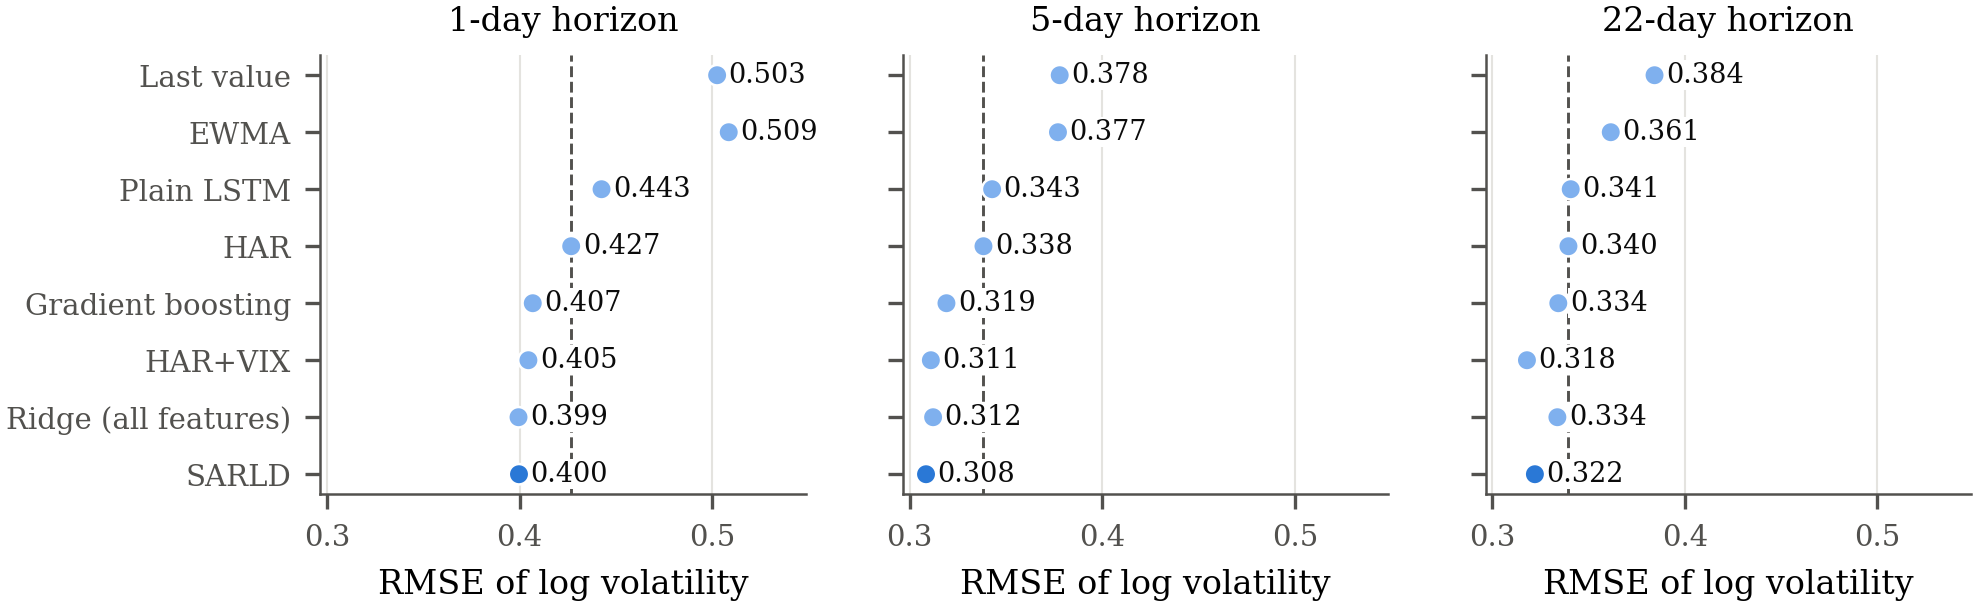

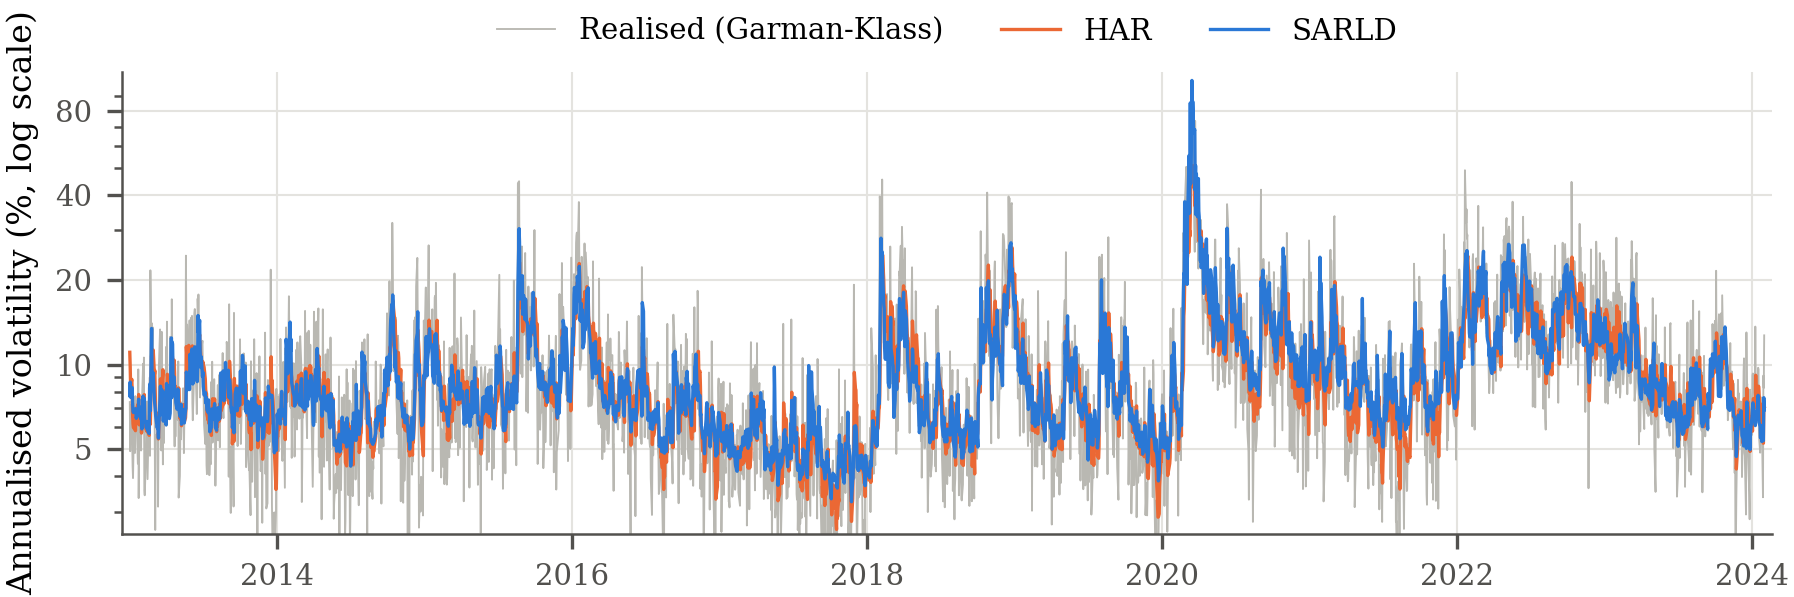

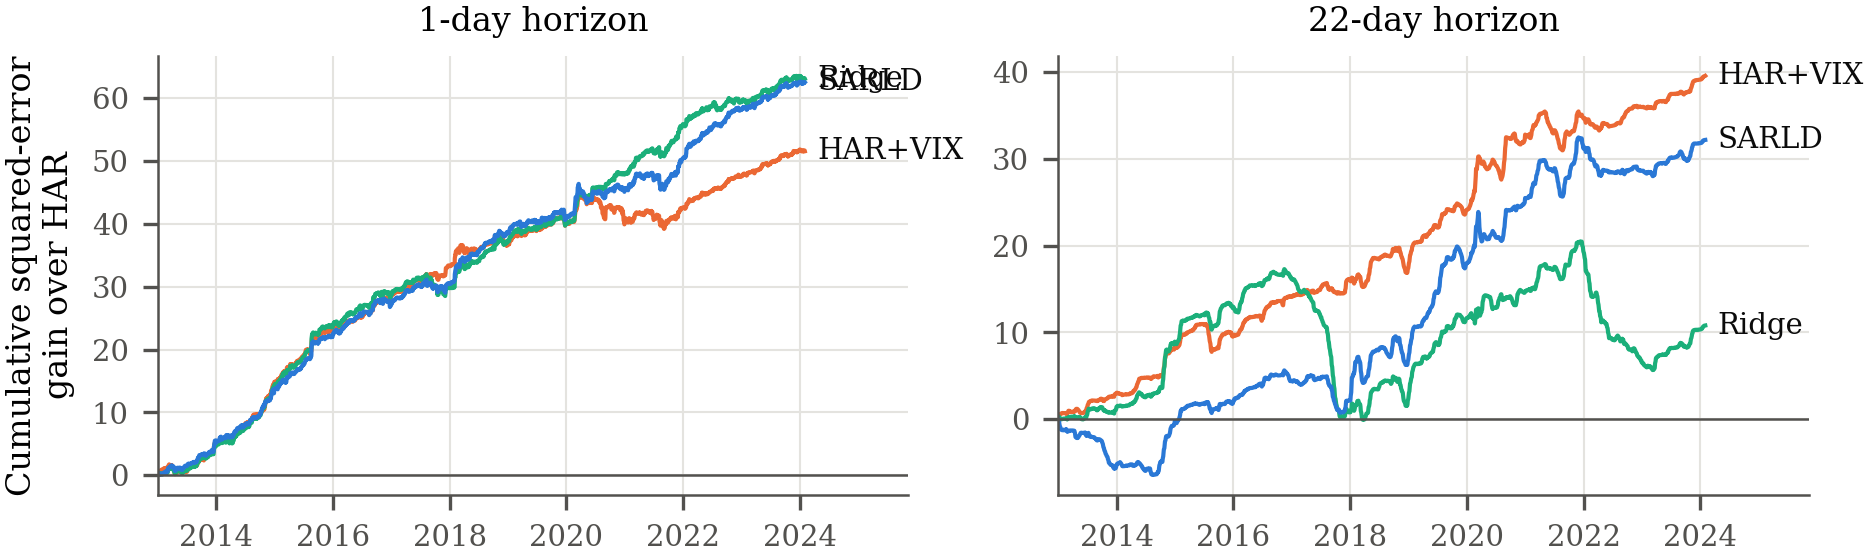

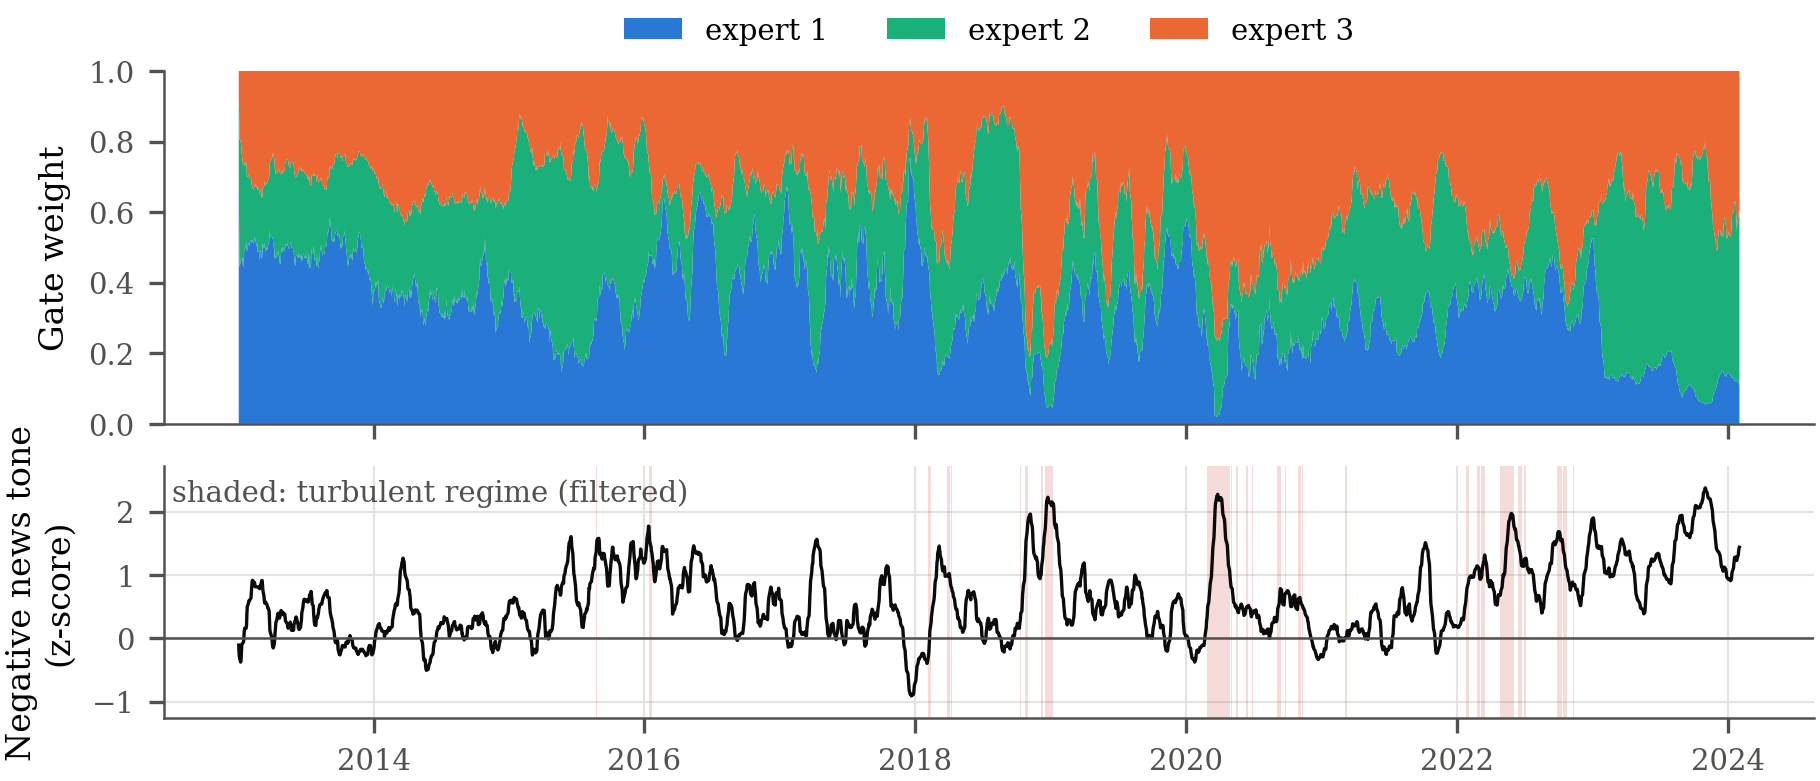

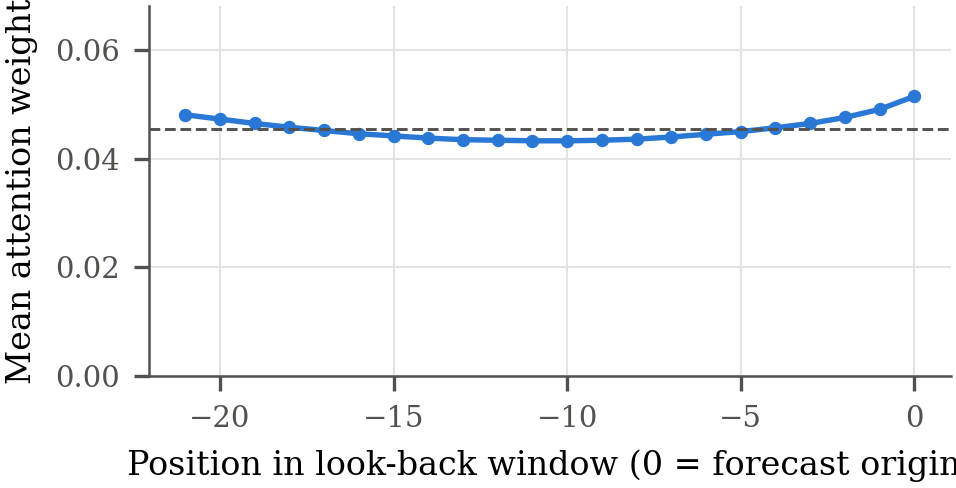

In [ ]:
from paper_extras import paper_extras, make_paper_figures
R, per_year = paper_extras(prep, OUT, SEEDS)
print('=== 1-day and 22-day RMSE by year ==='); print(per_year.round(4).to_string(index=False), '\n')
print('=== joint (cross-horizon) DM test, SARLD against each model: [statistic, p] ===')
for k, v in R['joint_dm_full_vs'].items(): print(f'  {k:28s} {v}')
print('\n=== gate ==='); print(json.dumps({k: R[k] for k in R if k.startswith('gate')}, indent=1))
print('\nmean best epoch:', R['best_epoch_mean'])
make_paper_figures(OUT)
from IPython.display import Image, display
for n in ['paper_fig_rmse', 'paper_fig_forecast', 'paper_fig_cumgain', 'paper_fig_gate', 'paper_fig_attention']:
    display(Image(f'{OUT}/{n}.png', width=900))

## 8. Package the results
Send the downloaded `sarld_results.zip` back so the paper can be written from these numbers.

In [ ]:
import shutil
shutil.make_archive('sarld_results', 'zip', OUT)
print('created sarld_results.zip', round(os.path.getsize('sarld_results.zip') / 1e6, 1), 'MB')
try:
    from google.colab import files; files.download('sarld_results.zip')
except Exception as e:
    print('download it from the Files panel on the left')

created sarld_results.zip 11.0 MB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>